# Module 3 - Algorithm auditing: Accuracy, Fairness and Interpretability


### Assignment overview

In this assignment, you will be asked to evaluate a set of trained classifiers for accuracy, fairness and transparency. The classifiers have been trained on the [NIJ Recidivism Challenge Dataset](https://nij.ojp.gov/funding/recidivism-forecasting-challenge) to predict whether or not an individual will be arrested for a new crime within 3 years after being released on parole.

The assignment is modeled after “Accuracy, Fairness, and Interpretability of Machine Learning Criminal Recidivism Models, by Eric Ingram, Furkan Gursoy, Ioannis A. Kakadiaris (https://arxiv.org/abs/2209.14237).

For this assignment, it is possible to work in **groups of up to 2 students**.

### Group members
Leave blanks if group has less than 2 members:
- Student 1: Renata Liu
- Student 2: Christopher Chen


### Learning Goals:

After completing this week's lecture and tutorial work, you will be able to:
1. Describe different fairness metrics, such as statistical parity, equal opportunity and equal accuracy
2. Discuss fairness and fairness metrics from the perspective of multiple stakeholders
3. Define objective functions based on fairness metrics  
4. Evaluate a model’s transparency using strategies such as global surrogate models, permutation feature importance, and Shapley Additive Explanations (SHAP)
5. Evaluate common machine learning models based on their accuracy, fairness and interpretability
6. Describe how metrics such as accuracy and fairness need to be balanced for a trained model to have acceptable accuracy and low bias

In [2]:
%pip install eli5
%pip install aif360
%pip install aif360[reductions]

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
zsh:1: no matches found: aif360[reductions]
Note: you may need to restart the kernel to use updated packages.


## Import Libraries:

In [3]:
import pandas as pd
import numpy as np
import joblib

#fairness metrics
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.metrics import ClassificationMetric

from sklearn.metrics import (
   classification_report,
   confusion_matrix,
   f1_score,
   make_scorer,
   ConfusionMatrixDisplay,
   accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix
)

import matplotlib.pyplot as plt
import eli5
from sklearn.inspection import permutation_importance

# Part 1: Getting started:

Before starting this assignment, we ask you to read the paper it has been modeled after, to get an idea of the problem we are working on: https://arxiv.org/abs/2209.14237

You can also review the original dataset source [here](https://nij.ojp.gov/funding/recidivism-forecasting-challenge). The website includes a lot of information on the dataset and a detailed description of each of its columns (look for Appendix 2: Codebook).

Now that you have familiarized with the problem, you know that the goal is predicting the binary variable `Recidivism_Within_3years`, which indicates whether or not the person has committed a new felony or misdemeanour within 3 years from the beginning of parole supervision.

The National Institute of Justice’s (NIJ) obviously would want to deploy a highly accurate predictive model, to make sure that only deserving people get released on parole. Unfortunately, the existence of bias in the training set (typically historical or representation bias) makes it very likely to end up with an unfair classifier, that is, a classifier that produces different results for different protected classes of population.

Your job is to evaluate 4 classifiers, pre-trained and provided to you. This is called **algorithm auditing:** you are not the designer of the model, but you are in charge of evaluating its performance. Algorithm auditing can focus on various metrics and populations of interest, but in this case we will focus on evaluating **accuracy, fairness and transparency** of each algorithm.

To begin, load the dataset and classifiers by running the cells below:

In [4]:
train_df = pd.read_csv("training_set.csv")
test_df = pd.read_csv("testing_set.csv")

In [5]:
test_df.head()

,Unnamed: 0,ID,Gender,Race,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,...,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years,Recidivism_Arrest_Year1,Recidivism_Arrest_Year2,Recidivism_Arrest_Year3,Training_Sample
0,3735,3848,M,BLACK,48 or older,1,No,6.0,Standard,High School Diploma,...,0.0,0.0,1.00000,0.299385,No,No,No,No,No,0
1,5039,5174,M,BLACK,48 or older,20,No,2.0,Specialized,High School Diploma,...,0.0,0.0,1.00000,1.544397,No,Yes,No,No,Yes,1
2,16027,16485,F,WHITE,33-37,10,NaN,6.0,High,High School Diploma,...,0.0,0.0,0.51049,1.277098,No,No,No,No,No,1
3,18863,19486,F,WHITE,43-47,11,NaN,5.0,Standard,High School Diploma,...,0.0,0.0,1.00000,1.006198,No,No,No,No,No,1
4,14013,14408,M,WHITE,33-37,14,No,4.0,Standard,High School Diploma,...,0.0,0.0,1.00000,1.318592,No,No,No,No,No,1


In [6]:
#separating features
X_train, y_train = (
    train_df.drop(columns=["Recidivism_Within_3years"]),
    train_df["Recidivism_Within_3years"],
)

X_test, y_test = (
    test_df.drop(columns=["Recidivism_Within_3years"]),
    test_df["Recidivism_Within_3years"],
)

In [7]:
#loading classifiers
logreg_model  = joblib.load("models_for_A3/NIJ_logreg.joblib")
rf_model      = joblib.load("models_for_A3/NIJ_rf.joblib")
tree_model    = joblib.load("models_for_A3/NIJ_tree.joblib")
xgboost_model = joblib.load("models_for_A3/NIJ_xgboost.joblib")

/opt/anaconda3/envs/dsci430/lib/python3.11/pickle.py:1718: UserWarning: [21:23:20] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1789510470680/work/src/gbm/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


# Part 2: Classifiers' Accuracy (and other performance metrics):

First, we will evaluate each classifier's accuracy, together with other performance metrics that help us understanding how reliable the classifier's answers are. In addition to accuracy, we will use, **precision, recall and F1 score.**

### Question 1

Can you provide definition and formula for accuracy, precision, recall and F1 score, as a function of True Positives (TP), True Negatives (TN), False Positives (FP) and False Negatives (FN)?

It may help you use this table for reference:

<img src="ConfMatrix.png" alt="drawing" width="500"/>

Here, we are giving you the definition of AUC, as a reminder and example (note that the other metrics will need the formula):

**AUC:** AUC stands for Area Under the ROC curve. The ROC (receiver operating characteristic) curve is a plot of the recall and false positive rate of a classifier for different classification thresholds (see [here](https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc) for more details). AUC values go between 0 and 1. Higher values are more desirable as they indicate that the classifier is good at avoiding both false positives and false negatives. A value of 0.5 for a binary classification indicates that the classifier is no better at predicting the outcome than random guessing.

<u>Accuracy</u>: proportion of correct predictions out of all predictions made

(TP+TN)/(TP+TN+FN+FP)

<u>Precision</u>: out of all the positive predictions, how many are actually positive?

(TP)/(TP + FP)

<u>Recall</u>: out of all the positive labels, how well was the model able to find them

(TP)/(TP + FN)

<u>F1 Score</u>: harmonic mean of precision and recall

2*(recall * precision)/(recall + precision)



### Question 2

For every classifier given, calculate and report accuracy, precision, recall and F1 score on the test set. For ease of visualization and comparison, we will summarize these results in this dictionary:

In [8]:
results_dict = {}

There are different options available to us to compute fairness metrics, such as the many functions included in sklearn. For this exercise, however, we will focus on working with the [aif360](https://aif360.readthedocs.io/en/stable/Getting%20Started.html) library, an open source library designed specifically to examine and mitigate discrimination and bias in machine learning models.

Let's see in an example how we can use aif360 to compute standard performance metrics. We will start with the Random Forest model.

In [9]:
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# When using aif360, the target has to be numerical, so we will start by converting our target column. Since we are
# only interested in the metrics from the test set, we will convert only the test target

# Define your mapping
label_map = {"No": 0, "Yes": 1}

# Convert y_test
y_test_num = y_test.map(label_map)

# Since aif360 focuses on fairness, it needs us to identify the protected attribute we will use to segment the population.
protected_attr = 'pipeline-2__Race_WHITE'

# aif360 can not handle Nans - we must impute before converting. For this purpose, I can use the transformer included in
# the RF model
X_test_array = rf_model.named_steps['ct'].transform(X_test)

feature_names = rf_model.named_steps['ct'].get_feature_names_out()

X_test_transformed = pd.DataFrame(X_test_array, columns=feature_names, index=X_test.index)

# Locate protected attribute column in transformed test set.
protected_idx = X_test_transformed.columns.get_loc(protected_attr)

# Now that we have collected all this information, we can create a BinaryLabelDataset,
# aif360 base class for all structured datasets with binary labels - like ours!
# https://aif360.readthedocs.io/en/stable/modules/generated/aif360.datasets.BinaryLabelDataset.html#aif360.datasets.BinaryLabelDataset

aif_test = BinaryLabelDataset(
    favorable_label=1, # Being identified as not having committed a crime is the favorable outcome
    unfavorable_label=0,
    df=pd.concat([X_test_transformed, y_test_num], axis=1),
    label_names=[y_test.name],
    protected_attribute_names=[protected_attr]
)


In [10]:
# Now, we need to do a similar process and create a BinaryLabelDataset for the predictions of the Random Forest model

# First, we'll get the predictions and convert them to 0 and 1
y_pred = rf_model.predict(X_test)
y_pred_num = pd.Series(y_pred, index=y_test.index).map(label_map)

# Then, we will create a copy of the transformed test feature matrix and attach the predictions to it
pred_df = X_test_transformed.copy()
pred_df[y_test.name] = y_pred_num

# Finally, we piece everything together in a BinaryLabelDataset
aif_pred = BinaryLabelDataset(
    favorable_label=1,
    unfavorable_label=0,
    df=pred_df,
    label_names=[y_test.name],
    protected_attribute_names=[protected_attr]
)

In [11]:
# We are now ready to compute some metrics using aif_test (our ground truth) and aif_pred (our predictions)
classified_metric_rf = ClassificationMetric(
    aif_test,
    aif_pred,
    unprivileged_groups=[{protected_attr: 0}],
    privileged_groups=[{protected_attr: 1}]
)

precision = classified_metric_rf.precision()
recall = classified_metric_rf.recall()

# aif360 does not have a function foro F1 - we will compute F1 manually
if (precision + recall) > 0:
    f1 = 2 * (precision * recall) / (precision + recall)
else:
    f1 = 0.0

# Saving results in the dictionary
results_dict["RandomForest"] = {
    "accuracy": format(classified_metric_rf.accuracy(), ".3f"),
    "precision": format(precision, ".3f"),
    "recall": format(recall, ".3f"),
    "f1": format(f1, ".3f"),
}


In [12]:
pd.DataFrame(results_dict)

,RandomForest
accuracy,0.720
precision,0.740
recall,0.788
f1,0.763


Repeat the steps above for the logistic regression, decision tree, and xgboost model, and add the results to the dictionary.

### LogReg Model:

In [13]:
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric

label_map = {"No": 0, "Yes": 1}
protected_attr = 'pipeline-2__Race_WHITE'
y_test_num = y_test.map(label_map)

#define transformation
X_test_array = rf_model.named_steps['ct'].transform(X_test)
feature_names = rf_model.named_steps['ct'].get_feature_names_out()
X_test_transformed = pd.DataFrame(X_test_array, columns=feature_names, index=X_test.index)

aif_test = BinaryLabelDataset(
    favorable_label=1,
    unfavorable_label=0,
    df=pd.concat([X_test_transformed, y_test_num], axis=1),
    label_names=[y_test.name],
    protected_attribute_names=[protected_attr]
)

y_pred_lr = logreg_model.predict(X_test)
y_pred_lr_num = pd.Series(y_pred_lr, index=y_test.index).map(label_map)

pred_df_lr = X_test_transformed.copy()
pred_df_lr[y_test.name] = y_pred_lr_num

aif_pred_lr = BinaryLabelDataset(
    favorable_label=1,
    unfavorable_label=0,
    df=pred_df_lr,
    label_names=[y_test.name],
    protected_attribute_names=[protected_attr]
)

classified_metric_lr = ClassificationMetric(
    aif_test,
    aif_pred_lr,
    unprivileged_groups=[{protected_attr: 0}],
    privileged_groups=[{protected_attr: 1}]
)

precision_lr = classified_metric_lr.precision()
recall_lr = classified_metric_lr.recall()

if (precision_lr + recall_lr) > 0:
    f1_lr = 2 * (precision_lr * recall_lr) / (precision_lr + recall_lr)
else:
    f1_lr = 0.0

results_dict["LogisticRegression"] = {
    "accuracy": format(classified_metric_lr.accuracy(), ".3f"),
    "precision": format(precision_lr, ".3f"),
    "recall": format(recall_lr, ".3f"),
    "f1": format(f1_lr, ".3f"),
}

pd.DataFrame(results_dict)

,RandomForest,LogisticRegression
accuracy,0.720,0.709
precision,0.740,0.767
recall,0.788,0.708
f1,0.763,0.736


### Decision Tree Model:

In [14]:
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric

label_map = {"No": 0, "Yes": 1}
protected_attr = 'pipeline-2__Race_WHITE'
y_test_num = y_test.map(label_map)

#define transformation and tests
X_test_array = rf_model.named_steps['ct'].transform(X_test)
feature_names = rf_model.named_steps['ct'].get_feature_names_out()
X_test_transformed = pd.DataFrame(X_test_array, columns=feature_names, index=X_test.index)

aif_test = BinaryLabelDataset(
    favorable_label=1,
    unfavorable_label=0,
    df=pd.concat([X_test_transformed, y_test_num], axis=1),
    label_names=[y_test.name],
    protected_attribute_names=[protected_attr]
)

y_pred_dt = tree_model.predict(X_test)
y_pred_dt_num = pd.Series(y_pred_dt, index=y_test.index).map(label_map)

pred_df_dt = X_test_transformed.copy()
pred_df_dt[y_test.name] = y_pred_dt_num

aif_pred_dt = BinaryLabelDataset(
    favorable_label=1,
    unfavorable_label=0,
    df=pred_df_dt,
    label_names=[y_test.name],
    protected_attribute_names=[protected_attr]
)

classified_metric_dt = ClassificationMetric(
    aif_test,
    aif_pred_dt,
    unprivileged_groups=[{protected_attr: 0}],
    privileged_groups=[{protected_attr: 1}]
)

precision_dt = classified_metric_dt.precision()
recall_dt = classified_metric_dt.recall()

if (precision_dt + recall_dt) > 0:
    f1_dt = 2 * (precision_dt * recall_dt) / (precision_dt + recall_dt)
else:
    f1_dt = 0.0

results_dict["DecisionTree"] = {
    "accuracy": format(classified_metric_dt.accuracy(), ".3f"),
    "precision": format(precision_dt, ".3f"),
    "recall": format(recall_dt, ".3f"),
    "f1": format(f1_dt, ".3f"),
}

pd.DataFrame(results_dict)

,RandomForest,LogisticRegression,DecisionTree
accuracy,0.720,0.709,0.707
precision,0.740,0.767,0.699
recall,0.788,0.708,0.858
f1,0.763,0.736,0.771


### XGBoost Model:

In [15]:
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric

label_map = {"No": 0, "Yes": 1}
protected_attr = 'pipeline-2__Race_WHITE'
y_test_num = y_test.map(label_map)

#define transformation and tests
X_test_array = rf_model.named_steps['ct'].transform(X_test)
feature_names = rf_model.named_steps['ct'].get_feature_names_out()
X_test_transformed = pd.DataFrame(X_test_array, columns=feature_names, index=X_test.index)

aif_test = BinaryLabelDataset(
    favorable_label=1,
    unfavorable_label=0,
    df=pd.concat([X_test_transformed, y_test_num], axis=1),
    label_names=[y_test.name],
    protected_attribute_names=[protected_attr]
)

y_pred_xgb = xgboost_model.predict(X_test)
if pd.api.types.is_integer_dtype(y_pred_xgb):
    y_pred_xgb_num = pd.Series(y_pred_xgb, index=y_test.index).astype(int)
else:
    y_pred_xgb_num = pd.Series(y_pred_xgb, index=y_test.index).map(label_map)

pred_df_xgb = X_test_transformed.copy()
pred_df_xgb[y_test.name] = y_pred_xgb_num

aif_pred_xgb = BinaryLabelDataset(
    favorable_label=1,
    unfavorable_label=0,
    df=pred_df_xgb,
    label_names=[y_test.name],
    protected_attribute_names=[protected_attr]
)

classified_metric_xgb = ClassificationMetric(
    aif_test,
    aif_pred_xgb,
    unprivileged_groups=[{protected_attr: 0}],
    privileged_groups=[{protected_attr: 1}]
)

precision_xgb = classified_metric_xgb.precision()
recall_xgb = classified_metric_xgb.recall()

if (precision_xgb + recall_xgb) > 0:
    f1_xgb = 2 * (precision_xgb * recall_xgb) / (precision_xgb + recall_xgb)
else:
    f1_xgb = 0.0

results_dict["XGBoost"] = {
    "accuracy": format(classified_metric_xgb.accuracy(), ".3f"),
    "precision": format(precision_xgb, ".3f"),
    "recall": format(recall_xgb, ".3f"),
    "f1": format(f1_xgb, ".3f"),
}

pd.DataFrame(results_dict)

,RandomForest,LogisticRegression,DecisionTree,XGBoost
accuracy,0.720,0.709,0.707,0.741
precision,0.740,0.767,0.699,0.745
recall,0.788,0.708,0.858,0.833
f1,0.763,0.736,0.771,0.787


### Question 3

For every classifier given, plot the confusion matrices on training and test set. Here is another function you will find helpful for this task: [`confusion_matrix`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

#### Confusion Matrix - logistic regression:

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#log reg
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#train
y_pred_lr_train = logreg_model.predict(X_train)
cm_lr_train = confusion_matrix(y_train, y_pred_lr_train, labels=logreg_model.classes_)
disp_lr_train = ConfusionMatrixDisplay(confusion_matrix=cm_lr_train, display_labels=logreg_model.classes_)
disp_lr_train.plot(ax=axes[0], cmap='Blues')
axes[0].set_title("Logistic Regression - Train Set")

#test
y_pred_lr_test = logreg_model.predict(X_test)
cm_lr_test = confusion_matrix(y_test, y_pred_lr_test, labels=logreg_model.classes_)
disp_lr_test = ConfusionMatrixDisplay(confusion_matrix=cm_lr_test, display_labels=logreg_model.classes_)
disp_lr_test.plot(ax=axes[1], cmap='Blues')
axes[1].set_title("Logistic Regression - Test Set")

plt.show()

<Figure size 1200x500 with 4 Axes>

In [17]:
classified_metric_lr.binary_confusion_matrix(privileged=None)

{'TP': 3145.0, 'FP': 958.0, 'TN': 2352.0, 'FN': 1296.0}

#### Confusion Matrix - random forest:

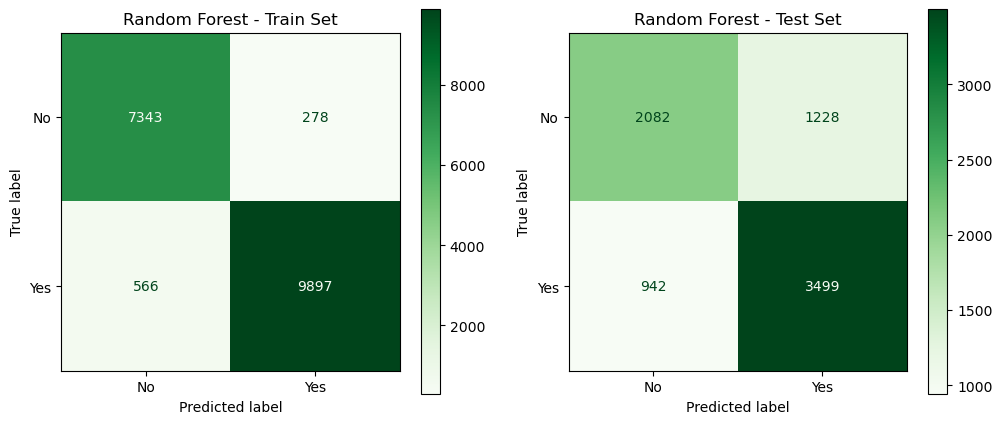

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#train
y_pred_rf_train = rf_model.predict(X_train)
cm_rf_train = confusion_matrix(y_train, y_pred_rf_train, labels=rf_model.classes_)
disp_rf_train = ConfusionMatrixDisplay(confusion_matrix=cm_rf_train, display_labels=rf_model.classes_)
disp_rf_train.plot(ax=axes[0], cmap='Greens')
axes[0].set_title("Random Forest - Train Set")

#test
y_pred_rf_test = rf_model.predict(X_test)
cm_rf_test = confusion_matrix(y_test, y_pred_rf_test, labels=rf_model.classes_)
disp_rf_test = ConfusionMatrixDisplay(confusion_matrix=cm_rf_test, display_labels=rf_model.classes_)
disp_rf_test.plot(ax=axes[1], cmap='Greens')
axes[1].set_title("Random Forest - Test Set")

plt.show()

In [19]:
classified_metric_rf.binary_confusion_matrix(privileged=None)

{'TP': 3499.0, 'FP': 1228.0, 'TN': 2082.0, 'FN': 942.0}

#### Confusion Matrix - decision tree:

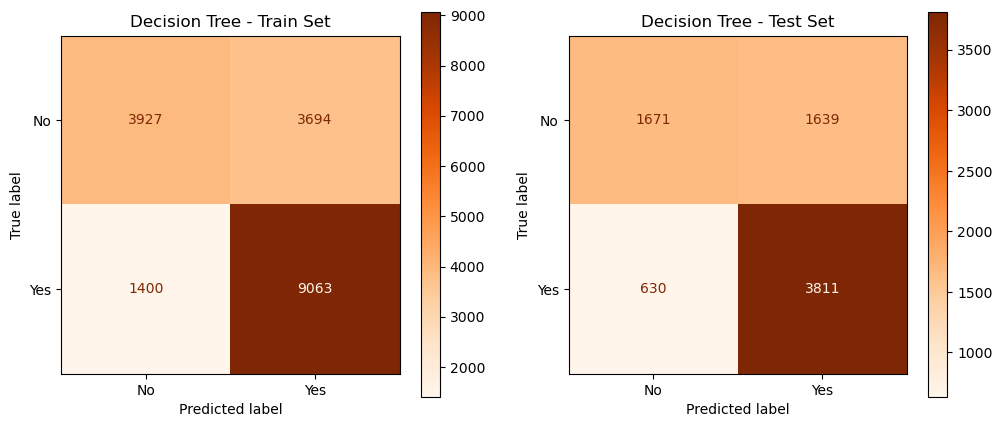

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#train
y_pred_dt_train = tree_model.predict(X_train)
cm_dt_train = confusion_matrix(y_train, y_pred_dt_train, labels=tree_model.classes_)
disp_dt_train = ConfusionMatrixDisplay(confusion_matrix=cm_dt_train, display_labels=tree_model.classes_)
disp_dt_train.plot(ax=axes[0], cmap='Oranges')
axes[0].set_title("Decision Tree - Train Set")

#test
y_pred_dt_test = tree_model.predict(X_test)
cm_dt_test = confusion_matrix(y_test, y_pred_dt_test, labels=tree_model.classes_)
disp_dt_test = ConfusionMatrixDisplay(confusion_matrix=cm_dt_test, display_labels=tree_model.classes_)
disp_dt_test.plot(ax=axes[1], cmap='Oranges')
axes[1].set_title("Decision Tree - Test Set")

plt.show()

In [21]:
classified_metric_dt.binary_confusion_matrix(privileged=None)

{'TP': 3811.0, 'FP': 1639.0, 'TN': 1671.0, 'FN': 630.0}

#### Confusion Matrix XGBoost:

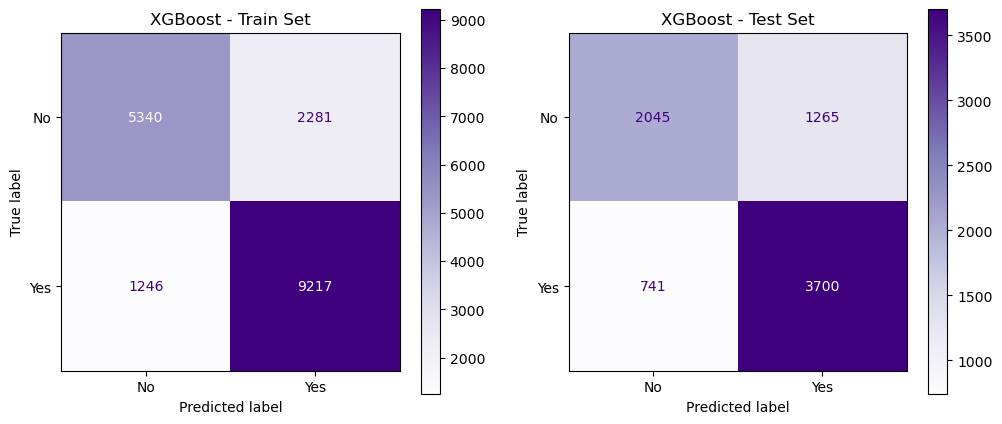

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#xgboost
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#map properly
xgb_classes = xgboost_model.classes_
display_labels = ['No', 'Yes'] if list(xgb_classes) == [0, 1] else xgb_classes

#train
y_pred_xgb_train = xgboost_model.predict(X_train)
#ensure training target is mapped for numerical
if list(xgb_classes) == [0, 1] and y_train.dtype == object:
    y_train_mapped = y_train.map({'No': 0, 'Yes': 1})
else:
    y_train_mapped = y_train

cm_xgb_train = confusion_matrix(y_train_mapped, y_pred_xgb_train, labels=xgb_classes)
disp_xgb_train = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_train, display_labels=display_labels)
disp_xgb_train.plot(ax=axes[0], cmap='Purples')
axes[0].set_title("XGBoost - Train Set")

#test
y_pred_xgb_test = xgboost_model.predict(X_test)
if list(xgb_classes) == [0, 1] and y_test.dtype == object:
    y_test_mapped = y_test.map({'No': 0, 'Yes': 1})
else:
    y_test_mapped = y_test

cm_xgb_test = confusion_matrix(y_test_mapped, y_pred_xgb_test, labels=xgb_classes)
disp_xgb_test = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_test, display_labels=display_labels)
disp_xgb_test.plot(ax=axes[1], cmap='Purples')
axes[1].set_title("XGBoost - Test Set")

plt.show()

In [23]:
classified_metric_xgb.binary_confusion_matrix(privileged=None)

{'TP': 3700.0, 'FP': 1265.0, 'TN': 2045.0, 'FN': 741.0}

### Question 4

Based on the results obtained so far, answer the following questions, providing an explanation and trying to base your decision on multiple metrics:
- Which classifiers would you choose for deployment?
- Which classifier is the most "severe" (a.k.a. classifies more people as at risk of committing another crime within 3 years)?
- Which classifier is the most cautious (a.k.a. classifies less people as at risk of committing another crime within 3 years)?

**RESPONSE**

1. I would choose the XGBoost model because it has the highest F1 score, meaning it is the best out of the models at balancing precision and recall.
2. To determine which model classifies more people at risk of committing another crime within 3 years, we need to calculate (# of TP + # of FP).
- Log reg: 958+3145 = 4103
- Decision tree: 1639+3811 = 5450
- Random forest: 1228+3499 = 4727
- XG boost: 3700+1265 = 4965

The model that is the most severe is the Decision Tree model.

3. Using the same calculations as above, we see that the classifier that predicts fewer people at risk of committing another crime within 3 years is the logistic regression model.

# Part 3 :  Fairness Evaluation:

Now that we have an understanding of how accurate our classifiers are across all samples, we need to measure their *fairness* across different categories. In similar problems, we are typically concerned with the classifiers being fair across different segments of protected populations (e.g. different genders or ethnicities). The original paper evaluates fairness for both gender and race, but for the purpose of this exercise we will only look at fairness across race, that is, for white and Black defendants.

### Question 5

As we have seen in class, there is not just one fairness metric, but several, as they have different ways to identify different treatments across populations. The metrics used in the paper are:

1. *Predicted Positive Rate Disparity (PPRD)*, whether the numbers of positive predictions are on par across groups.
2. *Predicted Positive Group Rate Disparity (PPGRD)*, whether the rates of positive predictions are on par across groups.
3. *False Discovery Rate Disparity (FDRD)*, whether the ratios of false positives to predicted positives are on par across groups.
4. *False Positive Rate Disparity (FPRD)*, whether the ratios of false positives to actual negatives are on par across groups.
5. *False Omission Rate Disparity (FORD)*, whether the ratios of false negatives to predicted negatives are on par across groups.
6. *False Negative Rate Disparity (FNRD)*, whether the ratios of false negatives to actual positives are on par across groups.

Before jumping into code writing, we must make sure that we have a solid understanding of how these metrics are computed from the True Positive, True Negative, False Positive, and False Negative values *for each group*. We will add the subscript *b* and *w* when appropriate to identify metrics from the group of black or white defendants, respectively. Then, we will write the equations for all fairness metrics. The first one is provided to you as an example:

| Metric    | Formula |
| :-------- | :------- |
| PPRD  |  $\frac{TPb + FPb}{TPw + FPw}$  |
| PPGRD | $\frac{(TPb + FPb)}{(TPb + FPb + TNb + FNb)} / \frac{(TPw + FPw)}{(TPw + FPw + TNw + FNw)}$   |
| FDRD | $\frac{FPb}{FPb + TPb}$ / $\frac{FPw}{FPw + TPw}$ |
| FPRD | $\frac{FPb}{TNb + FPb}$ / $\frac{FPw}{TNw + FPw}$  |
| FORD | $\frac{FNb}{FNb + TNb}$ / $\frac{FNw}{FNw + TNw}$  |
| FNRD | $\frac{FNb}{TPb + FNb}$ / $\frac{FNw}{TPw + FNw}$  |


## Question 6

Now that we have our formulas, let's test them by manually calculating some fairness metrics based on these two hypothetical confusion matrices:

| Confusion Matrix Group A | | | Confusion Matrix Group B |  | |
|--------------------|--|--|--------------------|--|--|
|        | Pred 1 | Pred 0 |        | Pred 1 | Pred 0 |
| **Actual 1** | 55 | 5 | **Actual 1** | 30 | 30 |
| **Actual 0** | 30 | 410 | **Actual 0** | 20 | 420 |

Helping yourself with the table from Question 5, compute the PPGDR, FPRD and FNRD for this scenario, using Group A as the reference (denominator). If we assumed that the positive class (1) represents the most desirable outcome, which group is at an advantage? Explain your answer.

PPGRD = $\frac{(TPb + FPb)}{(TPb + FPb + TNb + FNb)} / \frac{(TPa + FPa)}{(TPa + FPa + TNa + FNa)}$

= $\frac{30+20}{500} / \frac{55+30}{500}$

= $\frac{10}{17}$

~= 0.588

FPRD = $\frac{FPb}{TNb + FPb} / \frac{(FPa)}{(TNa + FPa}$

= $\frac{20}{420 + 20} / \frac{(30)}{(410 + 30}$

= $\frac{20}{30}$

~= 0.667

FNRD = $\frac{FNb}{TPb + FNb} / \frac{FNa}{TPa + FNa}$

= $\frac{30}{30 + 30} / \frac{5}{55 + 5}$

= $\frac{30}{60} / \frac{5}{60}$

= 6

**Interpreting** Group A is at an advantage. A PPGRD of 0.588 means that the ratio in the denominator, which is the proportion of positive (1) labels assigned to group A, was larger than the proportion assigned to group B. Group A received more desirable 1 labels than group B. An FPRD of 0.667 means that a higher proportion of group A's actual negatives was wrongly assigned a desirable label compared to group B. An FNRD of 6 indicates that group B was incorrectly given an undesirable label (0) 6 times more than group A. All three of the metrics point to A being at an advantage.

## Question 7

Now we will move to computing a selection of fairness metrics on the 4 estimators we are testing, so that we may test if they are producing fair classifications. We will compute all the metrics, except for PPDR.

Since we will be using the `aif360` library, you will need to read its documentation to figure out which functions will give us the result we are looking for. Check the documentation on the [`ClassificationMetric` class](https://aif360.readthedocs.io/en/latest/modules/generated/aif360.metrics.ClassificationMetric.html#), and complete the table below with the correct methods. The first one is given as an example:

| Metric    | ClassificationMetric method |
| :-------- | :------- |
| PPGRD |  `disparate_impact()` |
| FDRD | `false_discovery_rate_difference()`  |
| FPRD |  `false_positive_rate_difference()` |
| FORD | `false_omission_rate_difference()`  |
| FNRD | `false_negative_rate_difference()`  |

## Question 8

We are finally ready to compute the fairness metrics on our models! Do so for all models, and add the results to `results_dict`, so that we may easily compare them later.

**Hint:** it is highly recommended to repurpose the `ClassificationMetric` objects created in Question 2.

### LogReg Model:

In [24]:
results_dict['LogisticRegression'].update({
    "PPGRD": classified_metric_lr.disparate_impact(),
    "FDRD": classified_metric_lr.false_discovery_rate_difference(),
    "FPRD": classified_metric_lr.false_positive_rate_difference(),
    "FORD": classified_metric_lr.false_omission_rate_difference(),
    "FNRD": classified_metric_lr.false_negative_rate_difference()
})

pd.DataFrame(results_dict)

,RandomForest,LogisticRegression,DecisionTree,XGBoost
accuracy,0.720,0.709,0.707,0.741
precision,0.740,0.767,0.699,0.745
recall,0.788,0.708,0.858,0.833
f1,0.763,0.736,0.771,0.787
PPGRD,NaN,1.04661,NaN,NaN
FDRD,NaN,0.009129,NaN,NaN
FPRD,NaN,0.041129,NaN,NaN
FORD,NaN,0.04244,NaN,NaN
FNRD,NaN,0.007418,NaN,NaN


### Random Forest Model:

In [25]:
results_dict['RandomForest'].update({
    "PPGRD": classified_metric_rf.disparate_impact(),
    "FDRD": classified_metric_rf.false_discovery_rate_difference(),
    "FPRD": classified_metric_rf.false_positive_rate_difference(),
    "FORD": classified_metric_rf.false_omission_rate_difference(),
    "FNRD": classified_metric_rf.false_negative_rate_difference()
})

pd.DataFrame(results_dict)

,RandomForest,LogisticRegression,DecisionTree,XGBoost
accuracy,0.720,0.709,0.707,0.741
precision,0.740,0.767,0.699,0.745
recall,0.788,0.708,0.858,0.833
f1,0.763,0.736,0.771,0.787
PPGRD,1.104297,1.04661,NaN,NaN
FDRD,0.003843,0.009129,NaN,NaN
FPRD,0.063302,0.041129,NaN,NaN
FORD,0.004463,0.04244,NaN,NaN
FNRD,-0.039139,0.007418,NaN,NaN


### Tree Model:

In [26]:
results_dict['DecisionTree'].update({
    "PPGRD": classified_metric_dt.disparate_impact(),
    "FDRD": classified_metric_dt.false_discovery_rate_difference(),
    "FPRD": classified_metric_dt.false_positive_rate_difference(),
    "FORD": classified_metric_dt.false_omission_rate_difference(),
    "FNRD": classified_metric_dt.false_negative_rate_difference()
})

pd.DataFrame(results_dict)

,RandomForest,LogisticRegression,DecisionTree,XGBoost
accuracy,0.720,0.709,0.707,0.741
precision,0.740,0.767,0.699,0.745
recall,0.788,0.708,0.858,0.833
f1,0.763,0.736,0.771,0.787
PPGRD,1.104297,1.04661,1.058346,NaN
FDRD,0.003843,0.009129,-0.001021,NaN
FPRD,0.063302,0.041129,0.055076,NaN
FORD,0.004463,0.04244,0.025199,NaN
FNRD,-0.039139,0.007418,-0.012036,NaN


### XGBoost Model:

In [27]:
results_dict['XGBoost'].update({
    "PPGRD": classified_metric_xgb.disparate_impact(),
    "FDRD": classified_metric_xgb.false_discovery_rate_difference(),
    "FPRD": classified_metric_xgb.false_positive_rate_difference(),
    "FORD": classified_metric_xgb.false_omission_rate_difference(),
    "FNRD": classified_metric_xgb.false_negative_rate_difference()
})

pd.DataFrame(results_dict)

,RandomForest,LogisticRegression,DecisionTree,XGBoost
accuracy,0.720,0.709,0.707,0.741
precision,0.740,0.767,0.699,0.745
recall,0.788,0.708,0.858,0.833
f1,0.763,0.736,0.771,0.787
PPGRD,1.104297,1.04661,1.058346,1.087631
FDRD,0.003843,0.009129,-0.001021,0.00409
FPRD,0.063302,0.041129,0.055076,0.060019
FORD,0.004463,0.04244,0.025199,0.005926
FNRD,-0.039139,0.007418,-0.012036,-0.028568


### Question 9

Based on the results obtained so far, answer the following questions, providing an explanation for each answer:
- Which model would you say exhibits the least amount of bias? Which one shows the most bias?
- Based on the application, which fairness metric(s) do you think should be the most important? Which one(s) could be taken less into consideration?
- Finally, based on the fairness results, which model would you pick for this application? Is your pick different from the one based on performance metrics alone?

**RESPONSE**

1. Logistic Regression shows the least bias. It is closest to the fair value on three of the five metrics: PPGRD (1.047, closest to 1), FPRD (0.041, the smallest gap) and FNRD (0.007, nearly zero). Meanwhile, the Random Forest model shows the most bias. It has the largest PPGRD (1.104), the largest FPRD (0.063) and the largest FNRD gap (-0.039).

2. In this application the positive label means “will be rearrested,” which we think is the more harmful outcome, since it can influence parole decisions, and can lead to people being wrongly flagged as high risk. Through this perspective, the most important metrics are FPRD and FDRD. The FPRD measures how often people who would not reoffend are wrongly labeled high risk. All four models show a positive gap (0.041 to 0.063), so the unprivileged group bears more wrongful flags. The FDRD measures whether a “will reoffend” prediction is equally reliable for both groups (predictive parity). All models are near zero, so this criterion is roughly satisfied. The metrics that can be taken less into consideration are PPGRD, FNRD, and FORD. PPGRD ignores the true labels, so a ratio above 1 may partly reflect real differences in base rates rather than model bias. FNRD and FORD matter for public safety (missed recidivists), but they capture the less harmful error for the individual. FNRD is also near zero or negative for most models.

3. Based on fairness, the logistic regression model seems to be the most fair. It has the lowest FPRD, the PPGRD closest to 1, and an FNRD near zero. Its weakest metric, FORD, is one of the less important ones for this application. It also has the highest precision (0.767), so its “will reoffend” predictions are the most reliable, which matters when false positives are costly. However, this decision differs from the one based on performance alone. XGBoost is best on accuracy (0.741) and F1 (0.787), and the Decision Tree is best on recall (0.858). Logistic Regression has the lowest recall (0.708), so it misses more people who do reoffend. The right choice depends on how much weight is placed on wrongful flags versus missed recidivists. If high recall is required, the Decision Tree is a reasonable compromise, with fairness close to Logistic Regression (FPRD 0.055, FDRD near 0) and much better recall.

# Part 4: Interpretability Evaluation:

Finally, we will evaluate the *interpretability* of our models. It is important to be able to explain how the model uses each feature to make its predictions and *why* a model has given a particular response for an individual - especially important when, like in this case, people's lives are being affected.

### Inherently Interpretable Models

Some models are known to be *inherently interpretable*, meaning we can decifer the model behavior by looking at its parameters. These models are also called "white-box" models. Logistic regression models and decision trees - in some cases - fall in this category.

### Question 10

Run the cells below and look at the weights of the logistic regression model. For simplicity, the cells below show the 10 most positive and 10 most negative coefficients. What features bring the prediction more toward the positive class? What other features push the prediction toward the negative class? Do you see any coefficients that may be unfairly influencing the decision?

**RESPONSE**

Features like age at release 18-22, gang affiliation, having delinquency reports (0.61), and having 10 or more prior felony arrest episodes (0.52) bring the prediction more toward the positive class. The features that push the prediction toward the negative class include age at release 48 or older (-0.80) and 43-47 (-0.43), percent days employed (-0.66), and attending 10 or more programs (-0.39).

Some coefficients that may be unfairly influencing the decision include age, gender, and prior arrest counts. Age has the strongest weight in the model (+0.88 for 18-22, -0.80 for 48 or older). Although it may predict recidivism statistically, it is a characteristic people cannot change, and using it means two people with identical behavior can receive different risk scores solely because of their age difference. For gender, the model assigns higher risk to men simply for being male. Even if this reflects real base rates, the person is judged by group membership rather than individual behaviour. Finally prior arrest counts can depend on policing practices and subjective labeling, and arrests are not convictions. If some communities are policed more heavily, their members accumulate more arrests regardless of actual behavior. This feature can act as a proxy for race or neighborhood even though race is not listed among the top coefficients.

In [ ]:
feature_names = np.array(logreg_model.named_steps['columntransformer'].get_feature_names_out())
coeffs = logreg_model.named_steps["logisticregression"].coef_.flatten()
coeff_df = pd.DataFrame(coeffs, index=feature_names, columns=["Coefficient"])
coeff_df_sorted = coeff_df.sort_values(by="Coefficient", ascending=False)

In [ ]:
coeff_df_sorted.head(10)

In [ ]:
coeff_df_sorted.tail(10)

### Question 11

Now, let's look at a particular sample and try to explain its prediction. We have picked this sample because its feature values make it a hard case, one very close to the threshold between positive and negative class:

In [28]:
hard_sample = X_test[5:6]

pd.DataFrame(hard_sample)

,Unnamed: 0,ID,Gender,Race,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,...,DrugTests_Cocaine_Positive,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Arrest_Year1,Recidivism_Arrest_Year2,Recidivism_Arrest_Year3,Training_Sample
5,13308,13676,M,WHITE,33-37,22,No,8.0,Standard,Less than HS diploma,...,0.0,0.0,0.033333,0.376221,0.59487,Yes,No,Yes,No,1


If you look at the ground truth for this sample you will see that this person has, in fact, committed a new crime within 3 years from release. But what is the prediction of the logistic regression model? Find the answer below:

In [29]:
logreg_model.predict(hard_sample)

array(['Yes'], dtype=object)

In [30]:
# The label for this sample is, in fact, 'Yes'
y_test[5]

'Yes'

Take a closer look at the feature values for this sample. What seems to have contributed the most to the final prediction? What feature pushed the most in the opposite direction?

The model predicts “Yes”, which matches the true label. The coefficients pushing toward “Yes” are Gender_M (+0.393), Condition_MH_SA_Yes (+0.341) and Prior_Revocations_Parole_Yes (+0.324). Gender is a fairness concern, because it is a fixed characteristic rather than a behavior.

Two features behave differently from what their coefficients suggest. Percent_Days_Employed has a negative coefficient (-0.664), but this person’s value (0.376, below average, about -0.26 standardized) means the contribution is positive (about +0.17), so low employment also pushes toward “Yes”. Jobs_Per_Year has a positive coefficient (+0.314), but this person’s below-average value (about -0.23 standardized) makes its contribution negative (about -0.07), so it pushes against “Yes”.

The sample sits near the threshold because several of the model’s strongest coefficients do not apply. The person is not gang-affiliated (+0.80), and at 33-37 is neither 18-22 (+0.88) nor 48 or older (-0.80).

### Question 12
We said that decision trees are also inherently interpretable - *potentially*. That is because, in theory, it is possible to look at the tree structure and to follow the path along the tree to see how each node influenced the decision. But this is only possible if the tree has a reasonably small size.

Run the cell below and see if you can tell what are the most influencial features in the decision tree model.

In [ ]:
from sklearn import tree

tree.plot_tree(tree_model["dt"],fontsize=10)
plt.figure(figsize=(10,6))
plt.show()

If the method above was not satisfactory, you can try visualizing all the rules of the decision tree as text. Is this any better?

In [ ]:
from sklearn.tree import export_text
tree_rules = export_text(tree_model.named_steps['dt'], feature_names=list(tree_model.named_steps['ct'].get_feature_names_out()))
print(tree_rules)

When it is not possible to interpret a decision tree because of its complex structure, we can still extract other information from it that will help us understand the features' importance in the decision. The code in the cell below extracts the feature importances from the model (line 3), then uses this information to create a bar plot of features sorted by importance. The feature importance extracted this way is based on [Gini Importance](https://www.codecademy.com/article/fe-feature-importance-final) (as it is done in the original paper), which reflects how the features were picked when building the decision tree.

In [ ]:
import seaborn as sns

feature_importances = tree_model.named_steps["dt"].feature_importances_

# Sort the feature importances from greatest to least using the sorted indices
sorted_indices = feature_importances.argsort()[::-1]
sorted_feature_names = tree_model.named_steps['ct'].get_feature_names_out()[sorted_indices[0:20]] # Output limited to top 20 features
sorted_importances = feature_importances[sorted_indices[0:20]]

# # Create a bar plot of the feature importances
sns.set(rc={'figure.figsize':(11.7,30)})
sns.barplot(x=sorted_importances, y=sorted_feature_names)

Comment on the features importance of the tree model, compared to those seen in the logistic regression model, as well as the original paper results. Also, **what is a big limitation of using feature importance, compared to observing the coefficient of the logistic regression model?**

Response:The top feature relied on by the decision tree is Percent_Days_Employed, and then Jobs_Per_Year which is likely correlated, and Supervision_Risk_Score_First and Avg_Days_per_DrugTest follow.

The regression model also highly values Percent_Days_Employed, followed by categorical labels like Age_At_Release_18-22 and Gang_Affiliated_yes.

The original paper finds the same results as the decision tree.

As for limitations, Gini Importance does not provide the  direction of a relationship, and it is very biased towards continuous features because they offer more split points, which can increase their perceived importance.

### Question 13

As before, we are interested in evaluating how the model classifies a particular sample. Let's start looking at the classification for our `hard_sample`. Is it correct?

In [ ]:
tree_model.predict(hard_sample)

We would like to be able to tell what sequence of rules has led to this final decision, but, for a tree this large, this can be difficult, unless we want to manually sift through the list of rules or write some elaborate custom code. In the next sections, we will see an alternative method (SHAP) to achieve this result.

Yes, the prediction made by the decision tree model is correct. It predicted Yes,(indicating recidivism), which matches the ground truth label from our earlier evaluation.

### Question 11: Evaluation of Non-inherently Interpretable Models Using a Surrogate Model

Models that are not inherently interpretable ("black box" models) can still be examined to understand how they used the available features to make their predictions. In fact, there are many strategies to do this. The first one we are going to see is through use of a **surrogate model.** In this case, we train another model - an inherently interpretable one, such as a logistic regressor - on the *predictions* of the black box model, and then we try to interpret *its parameters*. Let's complete the code below to do that on the 3 non-inherently interpretable models included in this exercise: Random Forest and XGBoost.

#### Surrogate for Random Forest Model

In [ ]:
# Step 1: create logistic regressor object.
# For simplicity, we will use the already existing "NIJ_logreg.joblib" and re-train it, instead of creating
# a new one. The reason for this decision is that NIJ_logreg.joblib already knows how to handle the features
# of this dataset, while a new one will need to be designed to do so.

surrogate_model_rf = joblib.load("models_for_A3/NIJ_logreg.joblib")

#fix incompatibility
if 'columntransformer' in surrogate_model_rf.named_steps:
    ct_step = surrogate_model_rf.named_steps['columntransformer']
elif 'ct' in surrogate_model_rf.named_steps:
    ct_step = surrogate_model_rf.named_steps['ct']

if ct_step is not None and hasattr(ct_step, 'force_int_remainder_cols'):
    ct_step.force_int_remainder_cols = False

# Step 2: train model on random forest predictions on the training set
y_pred_rf_train = rf_model.predict(X_train)
surrogate_model_rf.fit(X_train, y_pred_rf_train)

# Step 3: visualize weights of surrogate model, as we did for the original logistic regression model
eli5.explain_weights(surrogate_model_rf[-1], feature_names=surrogate_model_rf[:-1].get_feature_names_out())

Now that we have the weights of the surrogate model, what can we say about how the Random Forest model makes its predictions? What features seem more important? Are they similar to what we have seen for the other models so far?

Response:

 By analyzing the weights of the Random Forest surrogate model, we can observe several aspects of how the black-box model generates its predictions. The features that most strongly influence the model towards predicting recidivism include being young at release, in particular between eighteen and twenty-two years old, and having gang affiliation. These are followed closely by having a delinquency report and having ten or more prior felony arrest episodes.

But the features that first and foremost drive predictions in the negative direction (that is, that predict no recidivism) are being older at release (greater than or equal to forty-eight years of age) and percentage of days worked.

These patterns are very much in line with the initial models we have seen. The original Logistic Regression model, for instance, made the most important root split for our classifications about whether someone was likely to reoffend based on whether they were youth when they were released, whether they belonged to a gang, and how low their employment levels were; the top root split in the decision tree was based on the percentage of days employed. We're seeing the same core informational indicator set for each estimator, just through different modeling mechanisms.

**Note:** using a surrogate model is not always a very good strategy, because the simpler "white box" model is often unable to replicate the behavior of the most complex "black box" model. We can get a sense of how close the surrogate is approximating the original model by looking at the R<sup>2</sup> score. In the paper, they do so when trying to create a surrogate for XGBoost, and they explain:

*The R<sup>2</sup> value between the XGBoost predictions and the surrogate model predictions on the test set is 0.38. The surrogate model only explains 38% of the variance in the XGBoost model’s predictions*

Test this for the random forest surrogate model. How much variance is it able to capture?

**Hints:**
- Think carefully about what constitues the array of predictions and the array of ground truths in this case
- You may remember that R<sup>2</sup> is, in fact, a metric for regression, not for classification! How can we use R<sup>2</sup> in this case? There are various ways to approximate R<sup>2</sup> for classification, as explained [here](https://datascience.oneoffcoder.com/psuedo-r-squared-logistic-regression.html). We will use the simplest one and use **count R<sup>2</sup>**, which is simply the accuracy of the surrogate classifier

In [ ]:
from sklearn.metrics import r2_score
surrogate_pred = surrogate_model_rf.predict(X_train)

# compute count R2
count_r2_rf = accuracy_score(y_pred_rf_train, surrogate_pred)  # RF predictions are the "ground truth"
print(f"RF surrogate count R2: {count_r2_rf:.4f}")

Now, repeat the analysis through surrogate model for XGBoost. Comment on the results, including considerations on the following:
- What seem to be the most important features?
- How do the sets of most important features compare across models (do not forget logistic regression and decision tree in this comparison)?
- How good are the surrogate models, in terms of capturing the variance of the original model? Are they reliable?
- ...more thoughts of your choice...

#### Surrogate for XGBoost Model

In [ ]:
import joblib
import eli5
from sklearn.metrics import accuracy_score

# Step 1: load the surrogate model (re-using the logreg architecture setup)
surrogate_model_xgb = joblib.load('models_for_A3/NIJ_logreg.joblib')

# Address the potential column transformer compatibility setting
if 'columntransformer' in surrogate_model_xgb.named_steps:
    ct_step = surrogate_model_xgb.named_steps['columntransformer']
elif 'ct' in surrogate_model_xgb.named_steps:
    ct_step = surrogate_model_xgb.named_steps['ct']

if ct_step is not None and hasattr(ct_step, 'force_int_remainder_cols'):
    ct_step.force_int_remainder_cols = False

# Step 2: Fit the surrogate model using the training set predictions of XGBoost
y_pred_xgb_train = xgboost_model.predict(X_train)
surrogate_model_xgb.fit(X_train, y_pred_xgb_train)

# Step 3: Display the surrogate model feature weights
eli5.explain_weights(surrogate_model_xgb[-1], feature_names=surrogate_model_xgb[:-1].get_feature_names_out())

In [ ]:
#calculate count R2
surrogate_xgb_preds = surrogate_model_xgb.predict(X_train)
count_r2_xgb = accuracy_score(y_pred_xgb_train, surrogate_xgb_preds)
print(f"XGBoost Surrogate Model Count R2 (Accuracy): {count_r2_xgb:.4f}")

Response:

From the surrogate model weights, we observe, which features are having the most influence on the global models when trained on XGBoost predictions. The features, which pulled the highest weights in the direction of recidivism (positive values) are: gang affiliation (approximately 1.89) and the age at release between eighteen and twenty-two (approximately 1.72). This is followed by ten or more prior felony arrest episodes and a delinquency report.

But, the features that most strongly shift predictions toward no recidivism are being forty-eight years of age or older at release (coefficient around -1.92) and having a high percentage of days employed (coefficient around -1.92). These are closely followed by having exactly one prior felony arrest episode.

Let's compare these feature importances with our old estimators. For all of them, the models learned very stable features: young age at release, being part of a gang, high priors, and employment history are essentially the most important features in our baseline Logistic Regression, in our Decision Tree, in our Random Forest surrogate and in our XGBoost surrogate. The direction of the features and their order in the ranking are very similar.

With model fidelity, this XGBoost surrogate achieves a count R-squared of 0.8578. This measure shows that the simpler logistic regression surrogate can replicate roughly 85.78% of the complex XGBoost model's behavior on the training data. While this fidelity metric of about 86% is high enough to confidently identify global feature trends, consider remember that the surrogate does not capture 100% of the variance. That means, relying purely on the global surrogate approximation for individual-level risk calculations can introduce errors.

### Question 12: Evaluation of Non-inherently Interpretable Models Using Permutation Feature Importance

Another method used to interpret black box models is using feature permutation, which means changing the value of a feature and observing changes in the model's prediction error. More important features, when changed, will result in more frequent mistakes.

Luckily for us, Permutation Feature Importance already exists as a function in Scikit-Learn! All you have to do it is looking at the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html) to learn how it works, and apply it to the 3 non-inherently interpretable models of this exercise. Let's start with Random Forest.

#### Random Forest Model:

In [ ]:
# Use permutation_importance on the random forest model, and save the result in a variable called "out"
out = permutation_importance(rf_model, X_test, y_test, random_state=0)

After you are done, you can run the cell below to visualize the top 5 most important features in a bar chart. If you like, you can change the number of features shown or try other visualization methods.

In [ ]:
result = pd.DataFrame({"Name": X_test.columns, "Importance": out["importances_mean"], "STD": out["importances_std"]})
result = result.sort_values(by=['Importance'], ascending=False)

sns.set(rc={'figure.figsize':(11.7,7)})
sns.barplot(data=result[:5], y="Name", x="Importance")

Now, use Permutation Feature Importance on XGBoost.

**Hint:** these are more complex models; if you find that this task is taking too long, you may consider reducing the number of permutations using the parameter `n_repeats`. Be aware that this produces more variable results.

#### XGBoost Model:

In [ ]:
# Use permutation_importance on the XGBoost model on the test set with mapped numeric targets
out_xgb = permutation_importance(xgboost_model, X_test, y_test_mapped, random_state=0, n_repeats=5)

# Create a DataFrame to store feature importances and sort them
result_xgb = pd.DataFrame({
    "Name": X_test.columns,
    "Importance": out_xgb["importances_mean"],
    "STD": out_xgb["importances_std"]
})
result_xgb = result_xgb.sort_values(by=['Importance'], ascending=False)

# Plot the top 5 most important features
sns.set(rc={'figure.figsize':(11.7, 7)})
sns.barplot(data=result_xgb[:5], y="Name", x="Importance")
plt.title("XGBoost Model - Top 5 Permutation Feature Importances")
plt.show()

Now that you have completed your analysis of feature importance using permutation, comment on the results. How do the sets of most important features compare with each other? Are this results similar to what you observed using the surrogate model?

**RESPONSE** 

For both models, Percent_Days_Employed is by far the most important feature (about 0.056 for Random Forest and 0.124 for XGBoost), followed by Jobs_Per_Year (about 0.016 and 0.054) and Age_at_Release (about 0.010 and 0.012). The remaining top-5 features differ: Gang_Affiliated and THC-positive tests for Random Forest, and meth-positive tests and Avg_Days_per_DrugTest for XGBoost. XGBoost’s importances are larger overall, meaning shuffling a feature hurts its accuracy more, so it leans harder on the employment variables.

These results only partly match the surrogate models. The surrogates ranked gang affiliation, young age and prior felony arrests highest, while permutation puts employment first. Two reasons: permutation works on the original columns, so a feature like Age_at_Release is measured as one variable, whereas the surrogate splits it into one-hot columns, each with its own weight. Also, a large coefficient doesn’t mean shuffling the feature hurts accuracy, especially for rare categories like gang affiliation. Permutation importance also gives no direction, only magnitude.

### Question 13: Evaluation of Non-inherently Interpretable Models Using SHAP

The last method we are going to use to interpret the impact of each feature in our model is called SHAP, which stands for SHapley Additive exPlanations. How SHAP works is beyond the scope of this course, but if you are curious you can read the [original paper](https://arxiv.org/pdf/1705.07874.pdf) by Lundberg and Lee and check out [Lundberg's GitHub repo](https://github.com/shap/shap), which provides details on the implementation and examples.

You will need to install SHAP to be able to use it:
```
pip install shap
or
conda install -c conda-forge shap
```

Then, import it:

In [ ]:
%pip install shap

In [ ]:
import shap # may require to downgrade numpy to version = 1.23
shap.initjs()

SHAP needs the model (we will start with Random Forest) and samples to use to explain the predictions. For this, we will need to give it transformed samples (scaled and imputed, as required by the model) from  `X_train` or `X_test`.

In [ ]:
X_train_enc = pd.DataFrame(
    data=rf_model.named_steps['ct'].transform(X_train),
    columns=feature_names,
    index=X_train.index,
)

X_test_enc = pd.DataFrame(
    data=rf_model.named_steps['ct'].transform(X_test),
    columns=feature_names,
    index=X_test.index,
)

ind = np.random.choice(len(X_test_enc) - 1, 1000)
# This line just gives 1000 random indexes from the training set
# We do this because getting SHAP values for all samples would be a bit too long, but you
# are free to try it out!

ind = np.append(ind, 5) # adding the hard sample - we'll need this later

The following lines are all that's needed to explain the model's predictions for a set of samples:

In [ ]:
rf_explainer = shap.TreeExplainer(rf_model[-1])  # creating SHAP Explainer based on the model

rf_shap_values = rf_explainer.shap_values(X_test_enc.iloc[ind])  # explaining predictions for 1000 random samples

This gives us the SHAP values for each sample and each feature (values for the positive class):

In [ ]:
rf_shap_values[:,:,1]

This is hardly interpretable, though. It is better to get the average values for each feature, which returns something similar to feature importance:

In [ ]:
values = np.abs(rf_shap_values[:,:,1]).mean(0)
pd.DataFrame(data=values, index=feature_names, columns=["SHAP"]).sort_values(
    by="SHAP", ascending=False
)[:10]

The SHAP library also has a lot of ways to visualize and interpret the SHAP values - try it out!

In [ ]:
shap_figure = shap.summary_plot(rf_shap_values[:, :, 1], X_test_enc.iloc[ind], plot_size=[12,6])

Given the new information obtained using the SHAP library on the Random Forest model, explain the results (you will need to refer to the SHAP documentation - or ask us for help interpreting the plots) and comment on the difference between these results and those obtained using the other methods.


For the Random Forest model, the features with the highest mean absolute SHAP values are Percent_Days_Employed and Jobs_Per_Year, showing they have the strongest impact on predictions. High values of Percent_Days_Employed push risk scores in the negative direction, while low values and higher Supervision_Risk_Score_First push them toward a positive recidivism prediction. Unlike Gini Importance which only indicates magnitude, SHAP clearly reveals both the magnitude and direction of feature effects, and unlike a simple global surrogate model, it provides exact local consistency for individual predictions without approximation errors.

In [ ]:
# SHAP Analysis for XGBoost Model
# Create a SHAP explainer for the XGBoost classifier (the final step in the pipeline)
xgb_explainer = shap.TreeExplainer(xgboost_model[-1])

# Calculate SHAP values on the same subset of 1000 samples
xgb_shap_values = xgb_explainer.shap_values(X_test_enc.iloc[ind])

# Calculate mean absolute SHAP values to show feature importance
xgb_shap_df = pd.DataFrame(
    data=np.abs(xgb_shap_values).mean(0),
    index=feature_names,
    columns=["SHAP"]
).sort_values(by="SHAP", ascending=False)

display(xgb_shap_df.head(10))

# Generate the summary plot
shap.summary_plot(xgb_shap_values, X_test_enc.iloc[ind], plot_size=[12, 6])


Next, **repeat this analysis for XGBoost.**

In [ ]:
#SHAP explainer
xgb_explainer = shap.TreeExplainer(xgboost_model[-1])

#calculate SHAP values
xgb_shap_values = xgb_explainer.shap_values(X_test_enc.iloc[ind])

#calculate mean absolute SHAP values
xgb_shap_df = pd.DataFrame(
    data=np.abs(xgb_shap_values).mean(0),
    index=feature_names,
    columns=["SHAP"]
).sort_values(by="SHAP", ascending=False)

display(xgb_shap_df.head(10))

#display
shap.summary_plot(xgb_shap_values, X_test_enc.iloc[ind], plot_size=[12, 6])

### Question 14: Explaining individual predictions using SHAP

Another powerful feature of SHAP is that it allows us to explain the impact of each feature on individual predictions. For example, we will be able to explain how the prediction for our hard sample was generated. Let's start by looking at the prediction for this sample given by the random forest model. **Is it correct?**

In [ ]:
rf_model.predict(hard_sample)

**Response** Yes, the prediction is correct.

Let's look at the **waterfall plot** for this particular prediction, by running the cell below:

In [ ]:
shap.plots.waterfall(
    shap.Explanation(
        values=rf_shap_values[:, :, 1][-1],
        base_values=rf_explainer.expected_value[1],
        data=X_test_enc.iloc[ind[-1]],
        feature_names=X_test_enc.columns,
    )
)

**Interpret the plot results,**, including the following:
- What contributed the most to the prediction?
- What countered the prediction the most?
- Can we tell, by looking at the plot, that this was a difficult prediction?

**RESPONSE**

The Random Forest predicts “Yes” for this person, which matches the true label. The waterfall starts at the base value E[f(X)] = 0.50 (the average predicted probability of recidivism) and ends at f(x) = 0.628.

What contributed the most to the prediction?
Percent_Days_Employed is the largest contributor by far, adding +0.12 toward “Yes”. This person’s standardized value is -0.257, meaning their employment is below average, and low employment is associated with a higher risk of recidivism. The next largest push toward “Yes” is Supervision_Risk_Score_First (+0.03, value 0.805, an above-average initial risk score). Three more features add about +0.02 or +0.01 each: 3 or more prior property convictions, 5 or more prior property arrests, and prior parole revocations.

What countered the prediction the most?
No single feature stands out here. Several features each lower the score by about 0.02: Jobs_Per_Year (-0.226, below average job turnover), DrugTests_THC_Positive (-0.516, a below-average share of positive THC tests), not being gang-affiliated (Gang_Affiliated_Yes = 0), and not having 6 or more misdemeanor arrests (Prior_Arrest_Episodes_Misd_6 or more = 0). Together they take away part of what employment added.

Can we tell this was a difficult prediction?
Yes, to a fair extent. One feature (Percent_Days_Employed) accounts for most of the push toward “Yes”, while many small contributions of both signs offset each other and 115 other features add only about +0.01 in total. The final score of 0.628 is only about 0.13 above the 0.5 decision threshold, so there is no strong, consistent evidence either way. A small change in a few feature values, especially employment, could plausibly flip the prediction.

In [ ]:
import shap
import matplotlib.pyplot as plt

#set up shap explainer
xgb_explainer = shap.TreeExplainer(xgboost_model[-1])
xgb_shap_values_hard = xgb_explainer(X_test_enc.iloc[ind])

#display
plt.figure(figsize=(10, 6))
shap.plots.waterfall(xgb_shap_values_hard[-1], show=False)
plt.title("XGBoost Waterfall Plot - Hard Sample (Index 5)", pad=20)
plt.tight_layout()
plt.show()

In [ ]:
import shap
import matplotlib.pyplot as plt

#set up
dt_explainer = shap.TreeExplainer(tree_model[-1])
dt_shap_values_hard = dt_explainer(X_test_enc.iloc[ind])

#display
plt.figure(figsize=(10, 6))
shap.plots.waterfall(dt_shap_values_hard[-1][:, 1], show=False)
plt.title("Decision Tree Waterfall Plot - Hard Sample (Index 5)", pad=20)
plt.tight_layout()
plt.show()

Finally, **repeat the analysis and comment on the results of the individual predictions made on the hard sample by XGBoost and Decision Tree** (since we were not able to do the latter earlier).

Response:

The XGBoost model explanation for index 5 shows that high employment percentages and stable employment lower the predicted risk, while being male and having a high initial supervision risk score increase it. The positive and negative contributions largely cancel each other out, placing this sample close to the decision boundary and making it difficult to classify.

The Decision Tree model explanation for index 5 shows that the prediction of recidivism is mainly influenced by low employment rates and high initial risk scores. The model uses a series of binary decisions based on feature thresholds, including employment and age. Both XGBoost and the Decision Tree predict recidivism for this sample, but XGBoost considers a wider range of features, while the Decision Tree relies more heavily on its first few splits.

# Part 5: Final Evaluation:

### Question 15

Using **all the results collected so far** on accuracy, fairness and transparency of the 5 model, write your recommendation about what model, in your opinion, should be employed for this application (300 words max).

Response:

I recommend Logistic Regression, with XGBoost as the alternative if predictive performance matters most.

On accuracy, the models are close. XGBoost is best on accuracy (0.741) and F1 (0.787), and the Decision Tree has the highest recall (0.858). Logistic Regression has 0.709 accuracy and the highest precision (0.767), which matters because a false positive labels someone as high risk and can affect their parole. Its weakness is the lowest recall (0.708): it misses more people who do reoffend, so the deployer must decide whether wrongful flags or missed recidivists are costlier.

On fairness, Logistic Regression has the PPGRD closest to 1 (1.047) and the smallest FPRD (0.041), while Random Forest and XGBoost show the largest gaps (FPRD 0.063 and 0.060). Its weakest metric is FORD (0.042), which we consider less important here. Still, every model has a positive FPRD, so Black defendants are wrongly flagged more often by all four.

On transparency, logistic regression’s coefficients can be read directly, while the other models need surrogates, permutation importance or SHAP. These methods agree that employment, age and gang affiliation matter most, but the surrogates reproduce only 75-86% of the black-box predictions. Transparency also exposes concerns: the logistic regression uses age, gender and arrest counts that may reflect policing patterns, so these inputs need review before deployment.

Overall, Logistic Regression gives the best balance of fairness and transparency at a small cost in accuracy, and its decisions can be explained to the people they affect. It should support, not replace, human decision-makers.

# Final thoughts

1) If you have completed this assignment in a group, please write a detailed description of how you divided the work and how you helped each other completing it:

We went through the assignment together section by section and discussed ideas on how to answer each question. Then, to type up the full answers.

2) Have you used ChatGPT or a similar Large Language Model (LLM) to complete this homework? Please describe how you used the tool. We will never deduct points for using LLMs for completing homework assignments, but this helps us understand how you are using the tool and advise you in case we believe you are using it incorrectly.

We used LLMs to help with the formatting of displaying graphs with matplotlib

3) Have you struggled with some parts (or all) of this homework? Do you have pending questions you would like to ask? Write them down here!

Yes, this assignment was lengthy and required looking into documentation, which was time consuming. We have two questions: (1) AIF360 returns fairness metrics as differences while Q5 defines them as ratios. Is it fine to interpret them as differences from 0? (2) We computed the surrogate count R² on the training set, but the paper uses the test set. Which should we use?